<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/02_Model_and_Cityscapes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — SegFormer-B2 and Cityscapes Evaluation

This notebook evaluates a fixed pretrained semantic-segmentation model on the **Cityscapes validation set**.

The Cityscapes validation split contains **500 RGB images and 500 fine semantic ground-truth masks** and is retained as the standard clear-domain baseline.

The model is not fine-tuned, adapted, or modified.

This notebook is intentionally unchanged by the ACDC-specific protocol updates. ACDC invalid/uncertainty masks, matched normal/adverse correspondences, rare-class pair support, and bootstrap confidence intervals are handled in the later ACDC notebooks.

The main outputs are:

- Cityscapes clear-domain mIoU,
- IoU for each of the 19 Cityscapes semantic classes,
- the aggregate 19 × 19 confusion matrix,
- saved baseline result files used by the later cross-condition analyses.

Mount Drive and restore project paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/CV_Project")

DATASETS_DIR = PROJECT_ROOT / "datasets"
CONFIG_DIR = PROJECT_ROOT / "config"
RESULTS_DIR = PROJECT_ROOT / "results"
LOGS_DIR = PROJECT_ROOT / "logs"
MODELS_DIR = PROJECT_ROOT / "models"
NOTEBOOKS_DIR = PROJECT_ROOT / "Notebooks"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Project folders restored.")

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/CV_Project
Project folders restored.


Check whether prepared local data still exists

In [ ]:
LOCAL_DATA_ROOT = Path("/content/cv_data")

CITYSCAPES_RGB_DIR = (
    LOCAL_DATA_ROOT
    / "cityscapes"
    / "rgb"
    / "leftImg8bit"
    / "val"
)

CITYSCAPES_GT_ROOT = (
    LOCAL_DATA_ROOT
    / "cityscapes_gt"
)

print("Cityscapes RGB folder exists:",
      CITYSCAPES_RGB_DIR.exists())

print("Cityscapes GT folder exists:",
      CITYSCAPES_GT_ROOT.exists())

Cityscapes RGB folder exists: False
Cityscapes GT folder exists: False


Recreate Cityscapes local subset automatically if needed

In [ ]:
import zipfile

CITYSCAPES_RGB_ZIP = (
    DATASETS_DIR
    / "cityscapes"
    / "leftImg8bit.zip"
)

CITYSCAPES_GT_ZIP = (
    DATASETS_DIR
    / "archives"
    / "gtFine_trainvaltest.zip"
)

CITYSCAPES_RGB_OUT = (
    LOCAL_DATA_ROOT
    / "cityscapes"
    / "rgb"
)

CITYSCAPES_GT_OUT = (
    LOCAL_DATA_ROOT
    / "cityscapes_gt"
)

CITYSCAPES_RGB_OUT.mkdir(
    parents=True,
    exist_ok=True
)

CITYSCAPES_GT_OUT.mkdir(
    parents=True,
    exist_ok=True
)

Now extract RGB only if missing

In [ ]:
existing_rgb = list(
    CITYSCAPES_RGB_OUT.rglob(
        "*_leftImg8bit.png"
    )
)

if len(existing_rgb) == 500:

    print("Cityscapes RGB already prepared.")

else:

    print("Extracting Cityscapes validation RGB...")

    with zipfile.ZipFile(
        CITYSCAPES_RGB_ZIP,
        "r"
    ) as z:

        selected = [
            name
            for name in z.namelist()
            if name.startswith(
                "leftImg8bit/val/"
            )
            and name.endswith(
                "_leftImg8bit.png"
            )
        ]

        for i, name in enumerate(
            selected,
            start=1
        ):

            z.extract(
                name,
                CITYSCAPES_RGB_OUT
            )

            if i % 100 == 0:
                print(
                    f"{i}/{len(selected)}"
                )

    print("RGB extraction complete.")

Extracting Cityscapes validation RGB...
100/500
200/500
300/500
400/500
500/500
RGB extraction complete.


Extract Cityscapes validation masks if needed

In [ ]:
existing_gt = list(
    CITYSCAPES_GT_OUT.rglob(
        "*_gtFine_labelIds.png"
    )
)

if len(existing_gt) == 500:

    print("Cityscapes GT already prepared.")

else:

    print("Extracting Cityscapes validation GT...")

    with zipfile.ZipFile(
        CITYSCAPES_GT_ZIP,
        "r"
    ) as z:

        selected_gt = [
            name
            for name in z.namelist()

            if "__MACOSX" not in name

            and "/gtFine/val/" in name

            and name.endswith(
                "_gtFine_labelIds.png"
            )
        ]

        print(
            "Selected GT masks:",
            len(selected_gt)
        )

        for i, name in enumerate(
            selected_gt,
            start=1
        ):

            z.extract(
                name,
                CITYSCAPES_GT_OUT
            )

            if i % 100 == 0:
                print(
                    f"{i}/{len(selected_gt)}"
                )

    print("GT extraction complete.")

Extracting Cityscapes validation GT...
Selected GT masks: 500
100/500
200/500
300/500
400/500
500/500
GT extraction complete.


Verify final counts

In [ ]:
CITYSCAPES_RGB_DIR = (
    CITYSCAPES_RGB_OUT
    / "leftImg8bit"
    / "val"
)

cityscapes_images = sorted(
    CITYSCAPES_RGB_DIR.rglob(
        "*_leftImg8bit.png"
    )
)

cityscapes_gt_files = sorted(
    CITYSCAPES_GT_OUT.rglob(
        "*_gtFine_labelIds.png"
    )
)

print(
    "Cityscapes RGB:",
    len(cityscapes_images)
)

print(
    "Cityscapes GT:",
    len(cityscapes_gt_files)
)

Cityscapes RGB: 500
Cityscapes GT: 500


Install Transformers

In [ ]:
!pip -q install transformers

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from transformers import (
    AutoImageProcessor,
    SegformerForSemanticSegmentation
)

print("PyTorch:", torch.__version__)
print("CUDA available:",
      torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

PyTorch: 2.11.0+cpu
CUDA available: False


Select device

In [ ]:
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", DEVICE)

Using device: cpu


Load SegFormer-B2

In [ ]:
MODEL_NAME = (
    "nvidia/"
    "segformer-b2-finetuned-"
    "cityscapes-1024-1024"
)

print("Loading image processor...")

processor = (
    AutoImageProcessor
    .from_pretrained(MODEL_NAME)
)

print("Loading SegFormer-B2...")

model = (
    SegformerForSemanticSegmentation
    .from_pretrained(MODEL_NAME)
)

model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")

Loading image processor...


preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Loading SegFormer-B2...


config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Model loaded successfully.


Check the model's classes

In [ ]:
print(
    "Number of model labels:",
    model.config.num_labels
)

print()

for class_id, class_name in (
    model.config.id2label.items()
):
    print(
        class_id,
        "->",
        class_name
    )

Number of model labels: 19

0 -> road
1 -> sidewalk
2 -> building
3 -> wall
4 -> fence
5 -> pole
6 -> traffic light
7 -> traffic sign
8 -> vegetation
9 -> terrain
10 -> sky
11 -> person
12 -> rider
13 -> car
14 -> truck
15 -> bus
16 -> train
17 -> motorcycle
18 -> bicycle


Define our Cityscapes mapping again

In [ ]:
CITYSCAPES_ID_TO_TRAINID = {
    7: 0,
    8: 1,
    11: 2,
    12: 3,
    13: 4,
    17: 5,
    19: 6,
    20: 7,
    21: 8,
    22: 9,
    23: 10,
    24: 11,
    25: 12,
    26: 13,
    27: 14,
    28: 15,
    31: 16,
    32: 17,
    33: 18,
}

IGNORE_INDEX = 255


def cityscapes_labelids_to_trainids(
    label_array
):

    train_mask = np.full(
        label_array.shape,
        IGNORE_INDEX,
        dtype=np.uint8
    )

    for label_id, train_id in (
        CITYSCAPES_ID_TO_TRAINID.items()
    ):

        train_mask[
            label_array == label_id
        ] = train_id

    return train_mask

Choose one test image

In [ ]:
sample_image_path = (
    cityscapes_images[0]
)

print("Test image:")
print(sample_image_path)

Test image:
/content/cv_data/cityscapes/rgb/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit.png


In [ ]:
image = Image.open(
    sample_image_path
).convert("RGB")

print(
    "Original image size:",
    image.size
)

Original image size: (2048, 1024)


Find its matching ground-truth mask

In [ ]:
image_stem = (
    sample_image_path.name
    .replace(
        "_leftImg8bit.png",
        ""
    )
)

matching_gt = [
    path
    for path in cityscapes_gt_files
    if image_stem in path.name
]

print(
    "Matching GT masks:",
    len(matching_gt)
)

print(matching_gt[0])

Matching GT masks: 1
/content/cv_data/cityscapes_gt/gtFine_trainvaltest/gtFine/val/frankfurt/frankfurt_000000_000294_gtFine_labelIds.png


Load and convert ground truth

In [ ]:
gt_labelids = np.array(
    Image.open(
        matching_gt[0]
    )
)

gt_trainids = (
    cityscapes_labelids_to_trainids(
        gt_labelids
    )
)

print(
    "GT shape:",
    gt_trainids.shape
)

print(
    "Unique train IDs:",
    np.unique(gt_trainids)
)

GT shape: (1024, 2048)
Unique train IDs: [  0   1   2   4   5   7   8  10  11  13 255]


Run ONE prediction

In [ ]:
inputs = processor(
    images=image,
    return_tensors="pt"
)

pixel_values = (
    inputs["pixel_values"]
    .to(DEVICE)
)

print(
    "Model input shape:",
    pixel_values.shape
)

Model input shape: torch.Size([1, 3, 512, 512])


In [ ]:
with torch.inference_mode():

    outputs = model(
        pixel_values=pixel_values
    )

print(
    "Raw logits shape:",
    outputs.logits.shape
)

Raw logits shape: torch.Size([1, 19, 128, 128])


Resize logits to original image resolution

In [ ]:
import torch.nn.functional as F

target_height = (
    gt_trainids.shape[0]
)

target_width = (
    gt_trainids.shape[1]
)

upsampled_logits = F.interpolate(
    outputs.logits,

    size=(
        target_height,
        target_width
    ),

    mode="bilinear",

    align_corners=False
)

prediction = (
    upsampled_logits
    .argmax(dim=1)[0]
    .cpu()
    .numpy()
)

print(
    "Prediction shape:",
    prediction.shape
)

print(
    "Ground truth shape:",
    gt_trainids.shape
)

print(
    "Predicted classes:",
    np.unique(prediction)
)

Prediction shape: (1024, 2048)
Ground truth shape: (1024, 2048)
Predicted classes: [ 0  1  2  5  7  8 10 11 13]


Visualize Original / GT / Prediction

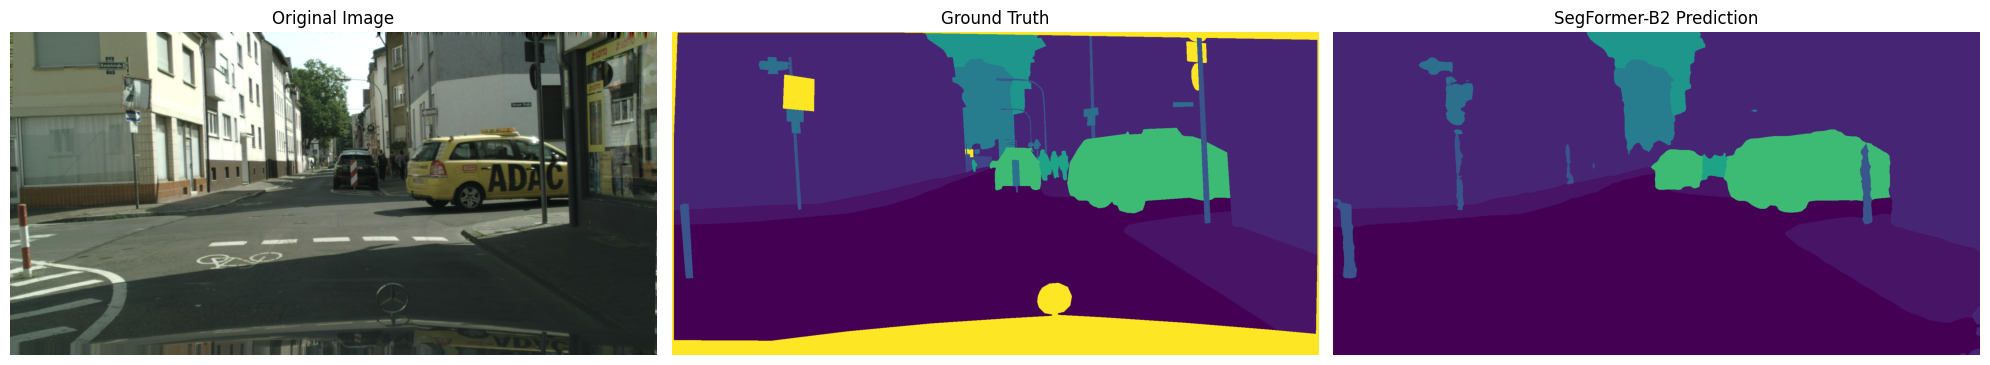

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7)
)

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

gt_display = gt_trainids.copy()
gt_display[
    gt_display == 255
] = 19

axes[1].imshow(
    gt_display,
    vmin=0,
    vmax=19
)
axes[1].set_title(
    "Ground Truth"
)
axes[1].axis("off")

axes[2].imshow(
    prediction,
    vmin=0,
    vmax=19
)
axes[2].set_title(
    "SegFormer-B2 Prediction"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

Check which classes occur

In [ ]:
CLASS_NAMES = [
    "road",
    "sidewalk",
    "building",
    "wall",
    "fence",
    "pole",
    "traffic light",
    "traffic sign",
    "vegetation",
    "terrain",
    "sky",
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]


print("Classes in ground truth:")

for class_id in np.unique(
    gt_trainids
):

    if class_id == 255:
        continue

    print(
        class_id,
        CLASS_NAMES[class_id]
    )


print("\nClasses predicted by model:")

for class_id in np.unique(
    prediction
):

    print(
        class_id,
        CLASS_NAMES[class_id]
    )

Classes in ground truth:
0 road
1 sidewalk
2 building
4 fence
5 pole
7 traffic sign
8 vegetation
10 sky
11 person
13 car

Classes predicted by model:
0 road
1 sidewalk
2 building
5 pole
7 traffic sign
8 vegetation
10 sky
11 person
13 car


## Full Cityscapes Evaluation

This section evaluates the fixed SegFormer-B2 model on all **500 Cityscapes validation images**.

The evaluation:

- uses the unchanged pretrained model,
- uses the official Cityscapes validation split,
- converts Cityscapes label IDs to the common 19 train IDs,
- ignores ground-truth void pixels with value `255`,
- accumulates one aggregate confusion matrix over all valid pixels,
- calculates the 19 per-class IoUs and the overall mIoU.

No ACDC uncertainty mask is used here because this notebook evaluates Cityscapes only.

Build fast image ↔ GT matching

In [ ]:
# Build a dictionary for quick GT lookup

gt_lookup = {}

for gt_path in cityscapes_gt_files:
    key = gt_path.name.replace(
        "_gtFine_labelIds.png",
        ""
    )
    gt_lookup[key] = gt_path

print("GT lookup entries:", len(gt_lookup))

GT lookup entries: 500


Confusion matrix helper

In [ ]:
NUM_CLASSES = 19

def update_confusion_matrix(
    confusion_matrix,
    ground_truth,
    prediction,
    num_classes=NUM_CLASSES
):
    # Ignore invalid/void pixels
    valid_mask = (
        (ground_truth != 255)
        & (ground_truth >= 0)
        & (ground_truth < num_classes)
    )

    gt = ground_truth[valid_mask]
    pred = prediction[valid_mask]

    # Safety check
    valid_pred = (
        (pred >= 0)
        & (pred < num_classes)
    )

    gt = gt[valid_pred]
    pred = pred[valid_pred]

    indices = (
        num_classes * gt.astype(np.int64)
        + pred.astype(np.int64)
    )

    bincount = np.bincount(
        indices,
        minlength=num_classes ** 2
    )

    confusion_matrix += bincount.reshape(
        num_classes,
        num_classes
    )

    return confusion_matrix

IoU calculation helper

In [ ]:
def calculate_iou(confusion_matrix):

    # True positives
    intersection = np.diag(confusion_matrix)

    # Ground-truth pixels per class
    gt_total = confusion_matrix.sum(axis=1)

    # Predicted pixels per class
    pred_total = confusion_matrix.sum(axis=0)

    # Union = GT + prediction - intersection
    union = (
        gt_total
        + pred_total
        - intersection
    )

    iou = np.full(
        len(intersection),
        np.nan,
        dtype=np.float64
    )

    valid_classes = union > 0

    iou[valid_classes] = (
        intersection[valid_classes]
        / union[valid_classes]
    )

    return iou

Run all 500 Cityscapes images

In [ ]:
from tqdm.auto import tqdm
import torch.nn.functional as F

confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

model.eval()

for image_path in tqdm(
    cityscapes_images,
    desc="Evaluating Cityscapes"
):

    # -------------------------
    # 1. Load RGB image
    # -------------------------
    image = Image.open(
        image_path
    ).convert("RGB")

    # -------------------------
    # 2. Find ground truth
    # -------------------------
    image_key = image_path.name.replace(
        "_leftImg8bit.png",
        ""
    )

    gt_path = gt_lookup[image_key]

    gt_labelids = np.array(
        Image.open(gt_path)
    )

    gt_trainids = (
        cityscapes_labelids_to_trainids(
            gt_labelids
        )
    )

    # -------------------------
    # 3. Preprocess image
    # -------------------------
    inputs = processor(
        images=image,
        return_tensors="pt"
    )

    pixel_values = (
        inputs["pixel_values"]
        .to(DEVICE)
    )

    # -------------------------
    # 4. Model inference
    # -------------------------
    with torch.inference_mode():

        outputs = model(
            pixel_values=pixel_values
        )

    # -------------------------
    # 5. Resize logits to GT size
    # -------------------------
    logits = F.interpolate(
        outputs.logits,
        size=gt_trainids.shape,
        mode="bilinear",
        align_corners=False
    )

    # -------------------------
    # 6. Get predicted class
    # -------------------------
    prediction = (
        logits.argmax(dim=1)[0]
        .cpu()
        .numpy()
    )

    # -------------------------
    # 7. Update confusion matrix
    # -------------------------
    confusion_matrix = (
        update_confusion_matrix(
            confusion_matrix,
            gt_trainids,
            prediction
        )
    )

Evaluating Cityscapes:   0%|          | 0/500 [00:00<?, ?it/s]

Calculate per-class IoU

In [ ]:
cityscapes_iou = calculate_iou(
    confusion_matrix
)

cityscapes_miou = np.nanmean(
    cityscapes_iou
)

print("Cityscapes per-class IoU:")
print()

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_id:2d} "
        f"{class_name:15s}: "
        f"{cityscapes_iou[class_id]:.4f}"
    )

print()
print(
    f"Cityscapes mIoU: "
    f"{cityscapes_miou:.4f}"
)

Cityscapes per-class IoU:

 0 road           : 0.9688
 1 sidewalk       : 0.7788
 2 building       : 0.8776
 3 wall           : 0.5330
 4 fence          : 0.4567
 5 pole           : 0.3891
 6 traffic light  : 0.4676
 7 traffic sign   : 0.5910
 8 vegetation     : 0.8753
 9 terrain        : 0.5998
10 sky            : 0.9004
11 person         : 0.6045
12 rider          : 0.3633
13 car            : 0.8974
14 truck          : 0.7001
15 bus            : 0.7718
16 train          : 0.6740
17 motorcycle     : 0.3577
18 bicycle        : 0.6053

Cityscapes mIoU: 0.6533


Put results in a table

In [ ]:
import pandas as pd

cityscapes_results = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": CLASS_NAMES,
    "iou": cityscapes_iou
})

cityscapes_results

,class_id,class_name,iou
0,0,road,0.968848
1,1,sidewalk,0.778813
2,2,building,0.877634
3,3,wall,0.533027
4,4,fence,0.456701
5,5,pole,0.389143
6,6,traffic light,0.467573
7,7,traffic sign,0.590998
8,8,vegetation,0.875278
9,9,terrain,0.599791


Add mIoU summary

In [ ]:
summary_df = pd.DataFrame({
    "dataset": ["Cityscapes"],
    "condition": ["clear"],
    "num_images": [len(cityscapes_images)],
    "mIoU": [cityscapes_miou]
})

summary_df

,dataset,condition,num_images,mIoU
0,Cityscapes,clear,500,0.653285


Save the results to Drive

In [ ]:
CITYSCAPES_RESULTS_DIR = (
    RESULTS_DIR / "cityscapes"
)

CITYSCAPES_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

per_class_csv = (
    CITYSCAPES_RESULTS_DIR
    / "cityscapes_per_class_iou.csv"
)

summary_csv = (
    CITYSCAPES_RESULTS_DIR
    / "cityscapes_summary.csv"
)

cityscapes_results.to_csv(
    per_class_csv,
    index=False
)

summary_df.to_csv(
    summary_csv,
    index=False
)

print("Saved:")
print(per_class_csv)
print(summary_csv)

Saved:
/content/drive/MyDrive/CV_Project/results/cityscapes/cityscapes_per_class_iou.csv
/content/drive/MyDrive/CV_Project/results/cityscapes/cityscapes_summary.csv


Save the confusion matrix

In [ ]:
confusion_path = (
    CITYSCAPES_RESULTS_DIR
    / "cityscapes_confusion_matrix.npy"
)

np.save(
    confusion_path,
    confusion_matrix
)

print("Confusion matrix saved:")
print(confusion_path)

Confusion matrix saved:
/content/drive/MyDrive/CV_Project/results/cityscapes/cityscapes_confusion_matrix.npy


Simple per-class IoU chart

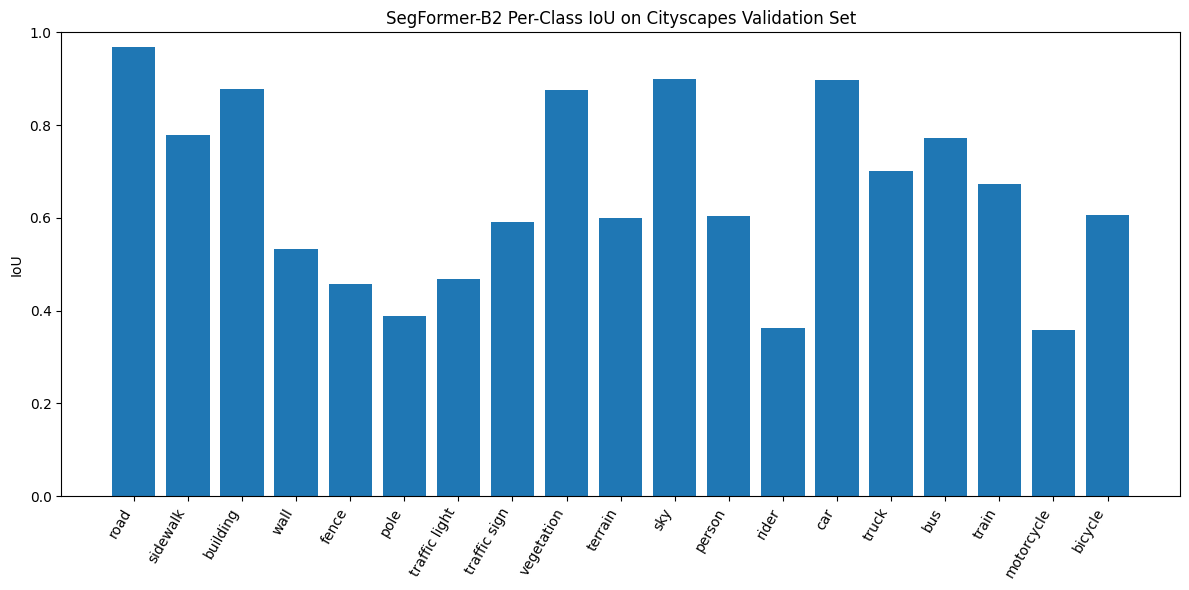

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    CLASS_NAMES,
    cityscapes_iou
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.ylabel("IoU")
plt.title(
    "SegFormer-B2 Per-Class IoU on Cityscapes Validation Set"
)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()